# Model Evaluation and Error Analysis

## Scope
Replay the recorded M3 results, inspect transfer behaviour, calculate new pixel metrics and demonstrate reference-isolated claim evaluation. Recorded learned scores are labelled separately from the fresh CPU controls. Model predictions generated by `scripts/caption_pairs.py` or pipeline workers can be passed to the same evaluation modules.

## 1. Setup

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.util
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/pipeline.json').exists()), None)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path('/content/TerraWatch')
    subprocess.run(['git','clone','--branch','model-pipeline','https://github.com/shoaib2000857/Group-7-DS-and-AI-Lab-Project.git',str(PROJECT_ROOT)],check=True)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from a clone of the model-pipeline branch.')
os.chdir(PROJECT_ROOT)
sys.path.insert(0,str(PROJECT_ROOT))
if IN_COLAB:
    subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements-pipeline.txt'],check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from datetime import datetime, timezone
plt.rcParams.update({'figure.figsize':(10,3.4),'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
RUN = PROJECT_ROOT/'outputs/model_notebooks'/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN.mkdir(parents=True,exist_ok=False)
PROCESSED = Path(os.environ.get('TERRAWATCH_PROCESSED',str(PROJECT_ROOT/'data/processed')))
CONFIG_PATH = PROJECT_ROOT/'configs/pipeline.json'
CONFIG = json.loads(CONFIG_PATH.read_text())
print('Run:',RUN)


Run: D:\IITM\DegreeTerm3\DSAI\Project\outputs\model_notebooks\20261110_163701_793954


## 2. Replay the local and historical caption screen

,Model,Historical (%),Local (%),Delta (pp)
0,RSCaMa (specialist),78.69,78.69,0.00
1,RSCaMa retrained on 20% (ours),79.17,76.04,-3.13
2,SmolVLM2-2.2B,38.58,37.76,-0.82
3,Qwen3-VL-4B,58.33,55.70,-2.63
4,Evidence template (pixel difference),69.00,69.00,0.00
5,"Constant ""there is no difference""",40.00,40.00,0.00


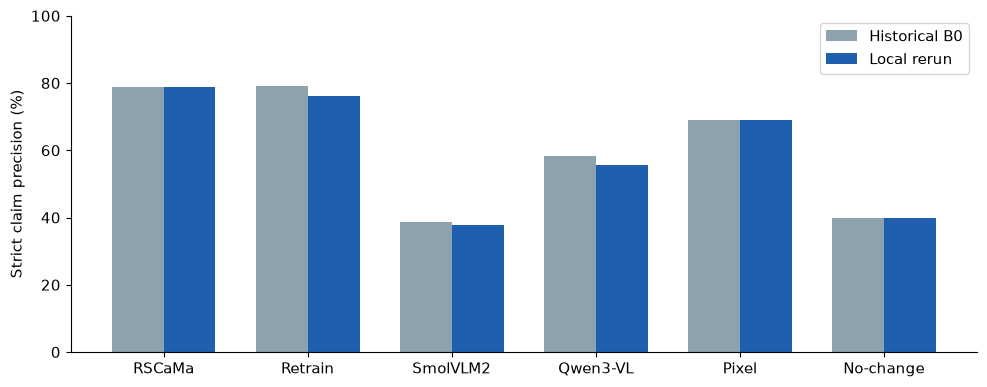

In [2]:
proof=json.loads(Path('docs/milestone3/evidence/caption_benchmark_proof.json').read_text())
records=[]
for row in proof['comparisons']:
    metric=row['metrics']['strict_precision']
    records.append({'Model':row['configuration'],'Historical (%)':100*metric['historical_b0_json'],'Local (%)':100*metric['local_rerun'],'Delta (pp)':metric['local_minus_historical_exact']})
table=pd.DataFrame(records);display(table.round(2))
fig,ax=plt.subplots(figsize=(10,4));x=np.arange(len(table));ax.bar(x-.18,table['Historical (%)'],.36,label='Historical B0',color='#8da2ad');ax.bar(x+.18,table['Local (%)'],.36,label='Local rerun',color='#1f5fae');ax.set_xticks(x,['RSCaMa','Retrain','SmolVLM2','Qwen3-VL','Pixel','No-change']);ax.set_ylabel('Strict claim precision (%)');ax.set_ylim(0,100);ax.legend();fig.tight_layout();plt.show()


## 3. Transfer and detector evidence

In [3]:
transfer=pd.DataFrame([{'Dataset':r['dataset'],'Pairs':r['sample_count_local'],'Strict (%)':100*r['metrics']['strict_precision']['local_rerun'],'BLEU-4':r['metrics']['BLEU-4']['local_rerun']} for r in proof['transfer_comparisons']]);display(transfer)
reported=json.loads(Path('docs/milestone3/evidence/reported_component_results.json').read_text())
detector=reported['detector'];display(pd.DataFrame([{'Detector':'BIT','Binary F1 (%)':detector['BIT_binary_f1_percent'],'False alarms':f"{detector['BIT_false_alarms']}/45"},{'Detector':'Otsu','Binary F1 (%)':detector['Otsu_binary_f1_percent'],'False alarms':f"{detector['Otsu_false_alarms']}/45"}]))
print('BIT class-mean IoU and Otsu binary IoU retain separate target definitions.')


,Dataset,Pairs,Strict (%),BLEU-4
0,SECOND-CC,100,48.04,0.2426
1,WHU-CDC,100,55.56,0.4717


,Detector,Binary F1 (%),False alarms
0,BIT,45.8,31/45
1,Otsu,16.7,45/45


BIT class-mean IoU and Otsu binary IoU retain separate target definitions.


## 4. Fresh control evaluation on prepared data
This cell runs Otsu on up to three prepared validation MCI pairs and compares its binary change output to their targets. It is a new control sample, separate from the frozen 100-pair local benchmark. In a clone without prepared data, an explicitly synthetic mask checks metric arithmetic.

fresh Otsu control on 3 prepared validation pairs


,pair_id,changed_pixels,predicted_pixels
0,levir_mci/val/val_000001,1106,26118
1,levir_mci/val/val_000002,2496,10515
2,levir_mci/val/val_000003,6986,14677


,pixels,macro_iou_present_classes,change_class_mean_iou,binary_precision,binary_recall,binary_f1,binary_iou,aggregation
0,196608,0.40618,0.084712,0.094212,0.456555,0.156192,0.084712,pooled pixels; class 0 background


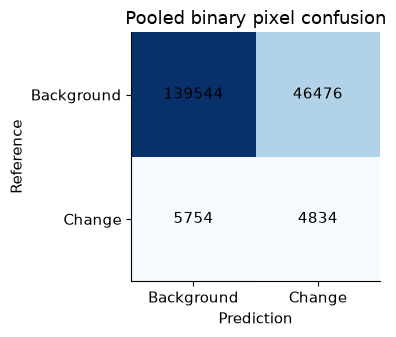

567

In [4]:
from src.evaluation.segmentation import confusion_matrix,metrics_from_confusion
from src.data.dataset import PairDataset
from PIL import Image
import cv2
manifest=PROCESSED/'val.jsonl';cm=np.zeros((2,2),dtype='int64');evaluation_rows=[]
if manifest.exists():
    dataset=PairDataset(manifest,PROCESSED)
    try:
        dataset.rows=[r for r in dataset.rows if r['dataset']=='levir_mci'][:3]
        for i in range(len(dataset)):
            sample=dataset[i];difference=np.abs(sample['t2'].astype(float)-sample['t1'].astype(float)).mean(-1).astype('uint8')
            _,prediction=cv2.threshold(difference,0,1,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
            target=(sample['targets']['target']>0).astype('uint8');cm+=confusion_matrix(target,prediction,2)
            evaluation_rows.append({'pair_id':sample['pair_id'],'changed_pixels':int(target.sum()),'predicted_pixels':int(prediction.sum())})
        metric_scope=f'fresh Otsu control on {len(dataset)} prepared validation pairs'
    finally:dataset.close()
else:
    target=np.array([[0,0,1],[0,1,1]],dtype='uint8');prediction=np.array([[0,1,1],[0,0,1]],dtype='uint8');cm=confusion_matrix(target,prediction,2);metric_scope='synthetic metric arithmetic fixture'
new_metrics=metrics_from_confusion(cm)
print(metric_scope);display(pd.DataFrame(evaluation_rows));display(pd.DataFrame([new_metrics]).drop(columns=['confusion_matrix','class_iou']))
fig,ax=plt.subplots(figsize=(4,3.5));ax.imshow(cm,cmap='Blues')
for (i,j),value in np.ndenumerate(cm):ax.text(j,i,str(value),ha='center',va='center',color='black')
ax.set_xticks([0,1],['Background','Change']);ax.set_yticks([0,1],['Background','Change']);ax.set_xlabel('Prediction');ax.set_ylabel('Reference');ax.set_title('Pooled binary pixel confusion');fig.tight_layout();plt.show()
(RUN/'new_control_metrics.json').write_text(json.dumps({'scope':metric_scope,**new_metrics},indent=2))


## 5. Fresh automatic caption checks
Only this evaluation driver reads source masks and reference captions. The inference worker receives images alone. The default predictions below are the deterministic no-change control, not RSCaMa outputs.

In [5]:
if manifest.exists():
    from src.evaluation.caption import PreparedTruth,evaluate_predictions
    dataset=PairDataset(manifest,PROCESSED,include_references=True)
    try:
        dataset.rows=[r for r in dataset.rows if r['dataset']=='levir_mci'][:3]
        predictions=[{'pair_id':r['pair_id'],'run_id':'fresh_no_change_control','raw_text':'there is no difference.','status':'ok'} for r in dataset.rows]
        summary=evaluate_predictions(predictions,PreparedTruth(dataset),RUN/'caption_control')
        display(pd.DataFrame([{k:summary[k] for k in ['pairs','supported_claim_precision_strict','reference_fact_recall','no_change_false_alarm_rate']}]))
    finally:dataset.close()
else:
    print('Prepared reference evaluation: run notebooks 01 and 02 to create the manifest and targets.')


,pairs,supported_claim_precision_strict,reference_fact_recall,no_change_false_alarm_rate
0,3,0.0,0.0,None


## 6. Human judgement and agreement
The protocol uses SUPPORTED, CONTRADICTED, UNSUPPORTED and UNVERIFIABLE. Two raters score independently; Cohen's kappa is calculated before third-rater adjudication. This notebook creates the input template and never fills human labels from model outputs.

In [6]:
template=pd.DataFrame(columns=['pair_id','claim_id','claim_text','rater_1','rater_2','adjudicated_label','adjudicator_notes'])
template.to_csv(RUN/'human_audit_template.csv',index=False)
print('Audit template:',RUN/'human_audit_template.csv')


Audit template: D:\IITM\DegreeTerm3\DSAI\Project\outputs\model_notebooks\20261110_163701_793954\human_audit_template.csv


## 7. Evaluate your own model outputs
The detector CLI expects JSONL rows with `pair_id` and `mask_path` (relative to that JSONL or absolute). Caption rows use `pair_id`, `raw_text`, `status` and `run_id`. Prediction IDs must belong to the chosen dataset/split. Mask dimensions and class indices are checked.

In [7]:
commands=[
'python scripts/caption_pairs.py --split val --limit 100 --output outputs/model_evaluation/captions.jsonl',
'python scripts/evaluate_models.py captions --split val --predictions outputs/model_evaluation/captions.jsonl --output outputs/model_evaluation/caption_metrics',
'python scripts/evaluate_models.py detector --split val --predictions outputs/model_evaluation/masks.jsonl --output outputs/model_evaluation/detector_metrics']
print('\n'.join(commands))


python scripts/caption_pairs.py --split val --limit 100 --output outputs/model_evaluation/captions.jsonl
python scripts/evaluate_models.py captions --split val --predictions outputs/model_evaluation/captions.jsonl --output outputs/model_evaluation/caption_metrics
python scripts/evaluate_models.py detector --split val --predictions outputs/model_evaluation/masks.jsonl --output outputs/model_evaluation/detector_metrics


## 8. Export evaluation results

In [8]:
from scripts.package_model_run import package_run
archive=package_run(RUN,RUN.parent/(RUN.name+'_results.zip'));print(archive)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))


D:\IITM\DegreeTerm3\DSAI\Project\outputs\model_notebooks\20261110_163701_793954_results.zip
